In [143]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from scipy.stats import binom, poisson
from math import sqrt

Verwachtingswaarde: E[X] = 2.5104
Variantie: Var(X) = 1.1875
Standaardafwijking: sigma = 1.0897
P(X <= 2) = 0.5200


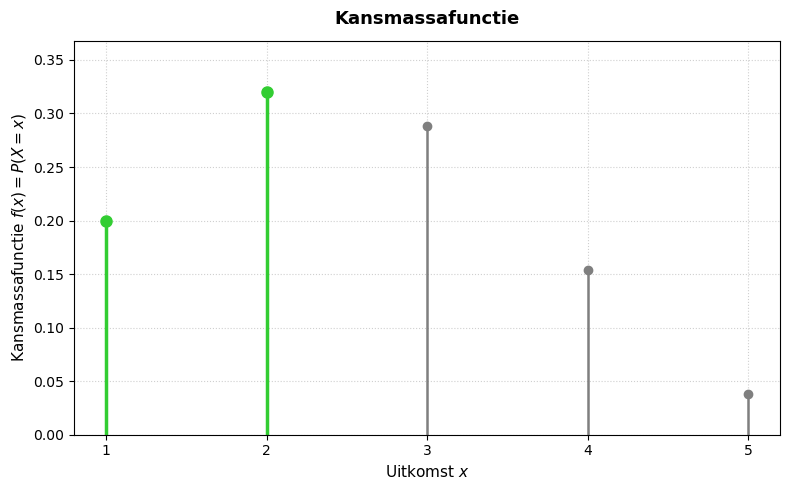

In [145]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from math import sqrt

def draw_stem_plot(
    outcomes,
    probabilities,
    highlight_condition=None,
    condition_label="Highlighted",
    title="Kansmassafunctie",
    filename="test.pdf"
):
    """
    Draws a stem plot for a discrete random variable and highlights stems matching a condition.
    
    :param highlight_condition: Function returning True for outcomes to highlight (e.g., lambda x: x <= 2)
    :param condition_label: Text description for the highlighted event (e.g., "$P(X \\le 2)$")
    """
    fig, ax = plt.subplots(figsize=(8, 5))
    
    # If no condition is provided, highlight nothing
    if highlight_condition is None:
        highlight_condition = lambda x: False

    # Separate outcomes and probabilities into highlighted and normal groups
    h_outcomes, h_probs = [], []
    n_outcomes, n_probs = [], []
    total_highlighted_prob = 0.0

    for x, p in zip(outcomes, probabilities):
        if highlight_condition(x):
            h_outcomes.append(x)
            h_probs.append(p)
            total_highlighted_prob += p
        else:
            n_outcomes.append(x)
            n_probs.append(p)

    # Plot default stems (Gray/Blue)
    if n_outcomes:
        markerline, stemlines, baseline = ax.stem(
            n_outcomes, n_probs, basefmt=" "
        )
        plt.setp(stemlines, color="#7f7f7f", linewidth=1.8)
        plt.setp(markerline, color="#7f7f7f", markersize=6)

    # Plot highlighted stems (Red/Orange)
    if h_outcomes:
        hl_label = f"{condition_label} = {total_highlighted_prob:.4f}"
        markerline_h, stemlines_h, baseline_h = ax.stem(
            h_outcomes, h_probs, basefmt=" "
        )
        plt.setp(stemlines_h, color="#32cd32", linewidth=2.5)
        plt.setp(markerline_h, color="#32cd32", markersize=8)

    # Labels and Formatting
    ax.set_xlabel("Uitkomst $x$", fontsize=11)
    ax.set_ylabel("Kansmassafunctie $f(x) = P(X = x)$", fontsize=11)
    ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
    ax.set_ylim(bottom=0, top=max(probabilities) * 1.15)
    
    plt.title(title, fontsize=13, weight="bold", pad=12)
    # plt.legend(loc="upper right", frameon=True, fontsize=10)
    plt.grid(True, linestyle=":", alpha=0.6)

    plt.tight_layout()
    plt.savefig(filename)
    plt.show()


# --- Calculation Functions ---
def compute_expected_value(probability_dict):
    return sum(k * v for k, v in probability_dict.items())

def compute_variance(probability_dict):
    mean = compute_expected_value(probability_dict)
    return sum((k - mean) ** 2 * v for k, v in probability_dict.items())

def compute_standard_deviation(probability_dict):
    return sqrt(compute_variance(probability_dict))

def P_leq(probability_dict, k):
    return sum(v for key, v in probability_dict.items() if key <= k)


# --- Example: Blood units per soldier ---
outcomes = [1, 2, 3, 4, 5]
probabilities = [0.2, 0.32, 0.288, 0.1536, 0.0384]
probability_dict = dict(zip(outcomes, probabilities))

# Calculations
expected_value = compute_expected_value(probability_dict)
variance = compute_variance(probability_dict)
std_dev = compute_standard_deviation(probability_dict)

print(f"Verwachtingswaarde: E[X] = {expected_value:.4f}")
print(f"Variantie: Var(X) = {variance:.4f}")
print(f"Standaardafwijking: sigma = {std_dev:.4f}")

# Target probability to highlight: P(X <= 2)
k_target = 2
p_val = P_leq(probability_dict, k_target)
print(f"P(X <= {k_target}) = {p_val:.4f}")

# Draw stem plot with condition X <= 2 highlighted
draw_stem_plot(
    outcomes,
    probabilities,
    highlight_condition=lambda x: x <= k_target,
    condition_label=f"$P(X \\leq {k_target})$",
    title="Kansmassafunctie",
    filename="test.png"
)

# Binomial distribution

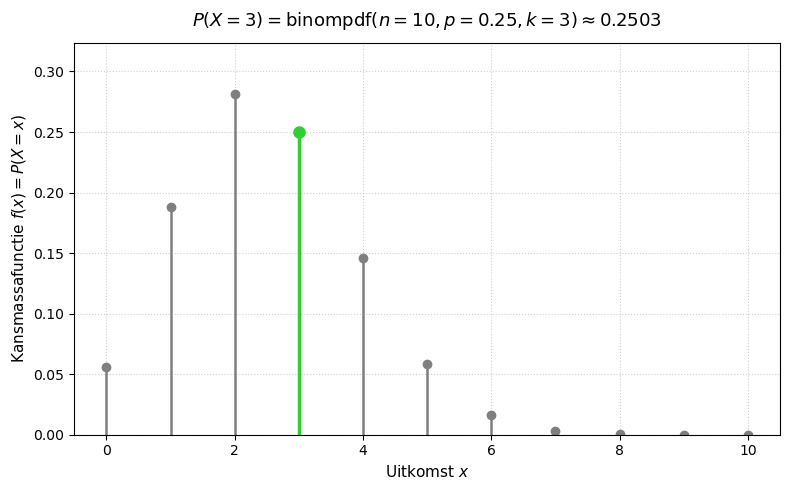

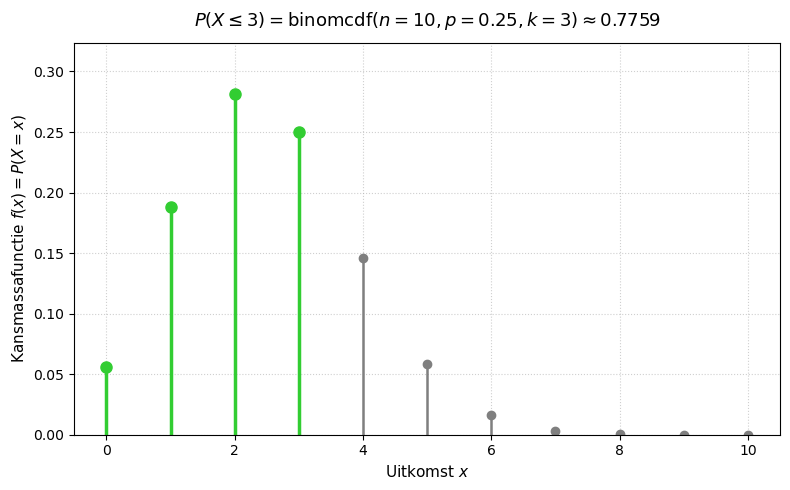

In [148]:
def draw_binompdf(n, p, k, filename):
    outcomes = np.array(range(n+1))
    probabilities = np.array([binom.pmf(i, n, p) for i in outcomes]) 
    P_eq = binom.pmf(k=k,n=n,p=p)
    title=f"$P(X={k}) = \\text{{binompdf}}(n={n}, p={p}, k={k}) \\approx {P_eq:.4f}$"
    draw_stem_plot(outcomes, probabilities, highlight_condition=lambda x: x == k, title=title, filename=filename)

def draw_binomcdf(n, p, k, filename):
    outcomes = np.array(range(n+1))
    probabilities = np.array([binom.pmf(i, n, p) for i in outcomes]) 
    P_leq = binom.cdf(k=k,n=n,p=p)
    title=f"$P(X\\leq{k}) = \\text{{binomcdf}}(n={n}, p={p}, k={k}) \\approx {P_leq:.4f}$"
    draw_stem_plot(outcomes, probabilities, highlight_condition=lambda x: x <= k, title=title, filename=filename)

n = 10
p = 0.25
k = 3

draw_binompdf(n, p, k, filename="./3_voorbeeld_binompdf.png")
draw_binomcdf(n, p, k, filename="./3_voorbeeld_binomcdf.png")

# Poisson distribution

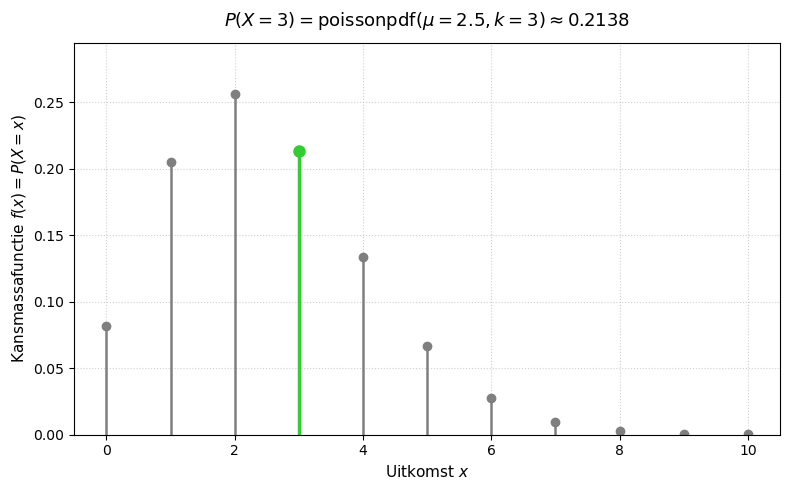

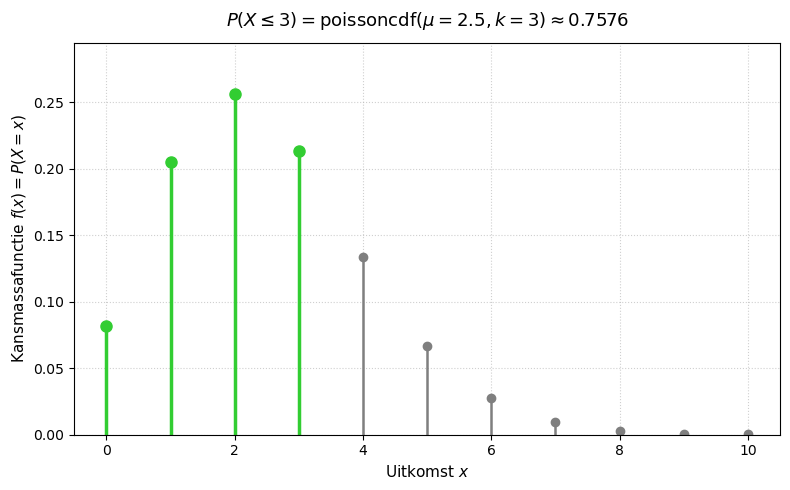

In [151]:
def draw_poissonpdf(mu, k, filename):
    outcomes = np.array(range(n+1))
    probabilities = np.array([poisson.pmf(i, mu) for i in outcomes]) 
    P_eq = poisson.pmf(k=k,mu=mu)
    title=f"$P(X={k}) = \\text{{poissonpdf}}(\\mu={mu}, k={k}) \\approx {P_eq:.4f}$"
    draw_stem_plot(outcomes, probabilities, highlight_condition=lambda x: x == k, title=title, filename=filename)

def draw_poissoncdf(mu, k, filename):
    outcomes = np.array(range(n+1))
    probabilities = np.array([poisson.pmf(i, mu) for i in outcomes]) 
    P_leq = poisson.cdf(k=k,mu=mu)
    title=f"$P(X\\leq{k}) = \\text{{poissoncdf}}(\\mu={mu}, k={k}) \\approx {P_leq:.4f}$"
    draw_stem_plot(outcomes, probabilities, highlight_condition=lambda x: x <= k, title=title, filename=filename)

mu = 2.5
k = 3

draw_poissonpdf(mu, k, filename="./3_voorbeeld_poissonpdf.png")
draw_poissoncdf(mu, k, filename="./3_voorbeeld_poissoncdf.png")